# 02 — Análise exploratória dos cartórios de MG

**Para que serve este notebook.** Conhecer o "formato" dos dados antes de qualquer modelo: como se distribuem a receita, os empregados e o passivo; como eles mudam por classe, situação, atribuição e região; como a arrecadação evoluiu desde 2007; e quais medidas andam juntas. Cada resultado vem com o que ele significa para o **mercado de seguro-garantia do Prov. 227**.

**Lembrete do mercado.** O Prov. 227 obriga as serventias **providas** (com titular) que **não são Classe 1** a garantir o passivo trabalhista. Quem tem bens ou fiança suficientes não precisa do seguro; o **déficit** é a parte do passivo que fica descoberta e que o seguro cobriria. As serventias **vagas** ficam fora, porque estão com um interino (no banco: `motivo = interinidade`). Os 10 números do painel estão no `docs/ESTADO_ATUAL.md`; este notebook **não muda** nenhum deles.

**Termos usados** (explicados com exemplo onde aparecem pela primeira vez): média, mediana, quartil, percentil, escala log, concentração, correlação de Spearman, valor real (descontada a inflação).

**Dados:** banco do pipeline (carga de 19/10/2026), cenário **base** com a regra de classe **v2** (Classe 1 até R$ 300 mil por semestre). Os gráficos também vão em PNG para `docs/qa/analises/`.

In [1]:
import sys
from pathlib import Path

raiz = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(raiz))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.colors import BoundaryNorm, ListedColormap

from src.analise import dados, enquadramento, estatistica as est, graficos as g
from src.notebooks import conectar, ler

g.estilo()
con = conectar()
sv = dados.serventias(con)
sv["passivo_obrigadas"] = sv["passivo"] * sv["peso_universo"]     # parte do passivo que conta no universo do Prov. 227
ar = dados.serie_arrecadacao(con)
print(f"{g.num(len(sv))} serventias ativas; obrigadas (≈): {g.num(sv.peso_universo.sum(), 1)}; "
      f"passivo de todas: {g.reais(sv.passivo.sum())}; das obrigadas: {g.reais(sv.passivo_obrigadas.sum())}; "
      f"déficit: {g.reais(sv.valor_descoberto.sum())}.")

2.525 serventias ativas; obrigadas (≈): 1.121,3; passivo de todas: R$ 311,9 mi; das obrigadas: R$ 238,1 mi; déficit: R$ 36,9 mi.


A linha acima reproduz os números 1, 3, 4, 5 e 7 do painel (2.525 serventias, ≈ 1.121 obrigadas, R$ 311,9 mi, R$ 238,1 mi e R$ 36,9 mi), o que confirma que estamos olhando os mesmos dados.

**Por que o número de obrigadas tem casa decimal (1.121,3).** As 78 serventias de classe indeterminada (sem receita válida em 2025; notebook 01) não contam como 0 nem como 1: cada uma entra com um **peso**, a probabilidade de não ser Classe 1, estimada pelas serventias que têm receita. A soma dos pesos dá um número fracionário; por isso o painel mostra "≈ 1.121".

## 1. Distribuições: receita, empregados CLT e passivo

**A pergunta.** Como é o cartório "típico" de MG, e quanto os grandes se afastam dele?

**O método.**
- **Média** = soma ÷ quantidade. **Mediana** = o valor do meio na fila ordenada. Exemplo: receitas de 10, 20, 30, 40 e 400 mil têm média de 100 mil, mas mediana de 30 mil. Quando a média fica muito acima da mediana, poucos valores grandes "puxam" a média: é a chamada **cauda longa**.
- **Quartis** dividem a fila em quatro partes iguais: 25% das serventias ficam abaixo do 1º quartil (Q1) e 75% abaixo do 3º (Q3). O **percentil 90** (P90) é o valor abaixo do qual ficam 90%.
- **Escala log**: no eixo, cada passo é "10 vezes mais" (R$ 10 mil, R$ 100 mil, R$ 1 milhão...). Sem ela, os cartórios pequenos ficariam todos espremidos num canto.
- **Concentração**: que parte do total está nos 10% (ou 1%) maiores.

Por que mediana e não média: com cauda longa, a média descreve mal o cartório típico.

,variável,n,media,mediana,q1,q3,p90,maximo,soma,media_sobre_mediana,10% maiores têm,1% maiores têm
0,Receita de referência 2025 (R$/semestre),2.447,"1.144.955,9","323.718,8","116.413,0","920.259,1","2.438.923,5","54.069.241,6","2.801.707.045,5","3,5","62,3%","20,0%"
1,Empregados CLT,2.521,"4,8","2,0","1,0","5,0","10,0","109,0","12.134,0","2,4","48,9%","13,4%"
2,Passivo estimado (R$),2.525,"123.511,6","42.951,5","19.946,2","99.521,1","241.040,5","4.323.326,8","311.866.725,1","2,9","60,5%","20,3%"


Base de todas as serventias (2.525): os 10% maiores têm 60,5% do passivo. Base das obrigadas (1.130 serventias com peso > 0, passivo × peso): os 10% maiores têm 53,5% do passivo das obrigadas.
Providas com receita a menos de 10% do limite da Classe 1 (para cima ou para baixo): 106.


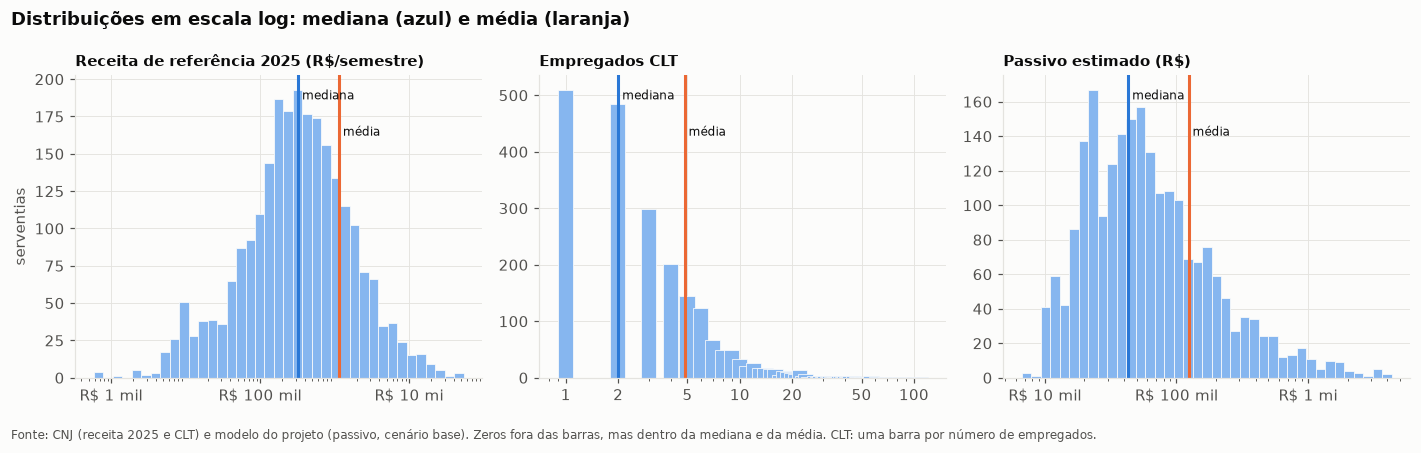

In [2]:
variaveis = {"receita_ref": "Receita de referência 2025 (R$/semestre)", "clt": "Empregados CLT", "passivo": "Passivo estimado (R$)"}
resumo = pd.DataFrame({nome: est.resumo(sv[col]) for col, nome in variaveis.items()}).T
resumo["10% maiores têm"] = [est.participacao_topo(sv[c], 0.10) for c in variaveis]
resumo["1% maiores têm"] = [est.participacao_topo(sv[c], 0.01) for c in variaveis]
fmt = {c: "num1" for c in ["media", "mediana", "q1", "q3", "p90", "maximo", "soma"]}
display(g.tabela(resumo.reset_index(names="variável"),
                 fmt | {"n": "int", "media_sobre_mediana": "num1", "10% maiores têm": "pct", "1% maiores têm": "pct"}))

# a tabela acima é sobre TODAS as serventias ativas; para o mercado, o que conta é o passivo das obrigadas
obrigadas = sv[sv.peso_universo > 0]
print(f"Base de todas as serventias ({g.num(len(sv))}): os 10% maiores têm {g.pct(resumo.loc[variaveis['passivo'], '10% maiores têm'])} "
      f"do passivo. Base das obrigadas ({g.num(len(obrigadas))} serventias com peso > 0, passivo × peso): os 10% maiores têm "
      f"{g.pct(est.participacao_topo(obrigadas.passivo_obrigadas, 0.10))} do passivo das obrigadas.")
perto = sv[(sv.situacao == "provida") & sv.receita_ref.between(0.9 * enquadramento.limites_classe()[0],
                                                               1.1 * enquadramento.limites_classe()[0])]
print(f"Providas com receita a menos de 10% do limite da Classe 1 (para cima ou para baixo): {g.num(len(perto))}.")

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, (col, nome) in zip(axes, variaveis.items()):
    s = sv[col][sv[col] > 0]
    if col == "clt":   # contagem inteira: uma barra por número de empregados (1, 2, 3...), da mesma largura no eixo log
        contagem = s.value_counts().sort_index()
        ax.bar(contagem.index, contagem.values, width=contagem.index * 0.2, color=g.AZUL["claro"],
               edgecolor=g.SUPERFICIE, linewidth=0.5)
    else:
        ax.hist(s, bins=np.logspace(np.log10(s.min()), np.log10(s.max()), 40), color=g.AZUL["claro"],
                edgecolor=g.SUPERFICIE, linewidth=0.5)
    ax.set_xscale("log")
    for valor, rotulo, cor, dy in ((sv[col].median(), "mediana", g.CORES[0], 0.92), (sv[col].mean(), "média", g.CORES[1], 0.80)):
        ax.axvline(valor, color=cor, linewidth=2)
        ax.text(valor, ax.get_ylim()[1] * dy, f" {rotulo}", color=g.TEXTO, fontsize=8)
    if col == "clt":
        ax.set_xticks([1, 2, 5, 10, 20, 50, 100])
        g.eixo_num(ax, "x")
    else:
        ax.set_xticks([1e3, 1e5, 1e7] if col == "receita_ref" else [1e4, 1e5, 1e6])
        g.eixo_reais(ax, "x")
    ax.set_title(nome, fontsize=10)
axes[0].set_ylabel("serventias")
fig.suptitle("Distribuições em escala log: mediana (azul) e média (laranja)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
g.nota(fig, "Fonte: CNJ (receita 2025 e CLT) e modelo do projeto (passivo, cenário base). Zeros fora das barras, "
            "mas dentro da mediana e da média. CLT: uma barra por número de empregados.")
g.salvar(fig, "02_distribuicoes_receita_clt_passivo")
plt.show()

**Como ler.** Cada barra conta quantas serventias têm valor naquela faixa (no CLT, uma barra por número de empregados). A linha azul (mediana) é o cartório típico; a laranja (média) é puxada pelos grandes.

**O que encontramos.**
- **Receita:** a serventia típica arrecada **R$ 324 mil por semestre**, praticamente **em cima do limite da Classe 1 (R$ 300 mil)**. A média é 3,5 vezes maior (R$ 1,14 milhão). Metade das serventias fica entre R$ 116 mil e R$ 920 mil (Q1 a Q3).
- **Empregados:** a típica tem **2 CLT**; 10% têm 10 ou mais; a maior, 109.
- **Passivo:** o típico é de **R$ 43 mil**; a média, R$ 124 mil.
- **Concentração**, sobre **todas as serventias ativas** (inclui vagas): os **10% maiores** têm **62% da receita** e **61% do passivo**; o **1%** maior (25 serventias), cerca de **20%** de cada. Sobre o **passivo das obrigadas** (o que importa para o mercado), os 10% maiores têm **53,5%**: a concentração continua alta, mas menor.

**O que significa para o Prov. 227.**
1. Como a mediana está colada no limite de R$ 300 mil, **pequenas mudanças** na receita ou no limite movem serventias entre a Classe 1 (dispensada) e a Classe 2 (obrigada): **106 providas** estão a menos de 10% do limite, para cima ou para baixo. O tamanho do universo é **sensível** ao limite e à correção dele pela inflação (art. 16, §2º, do Prov. 213; notebook 07).
2. O mercado é **concentrado**: poucas serventias grandes respondem pela maior parte do passivo e, portanto, do prêmio. Para uma seguradora, isso quer dizer poucos contratos grandes e muitos pequenos.

**Limitações.** A receita é a **arrecadação** declarada ao CNJ, não a "receita bruta" do art. 2º, XXIV, do Prov. 213 (a diferença é tema do notebook 08). O passivo é uma estimativa do modelo, não um dado observado. A receita dos 10% maiores inclui a serventia 042986, com um valor de 2025-2 quase certamente errado (notebook 01).

## 2. Por classe

**A pergunta.** Quanto do mercado está em cada classe?

**O método.** Agrupamos as serventias pela classe (regra v2) e somamos: quantas são, quantos CLT, quanto passivo, quantas são obrigadas (soma dos pesos do universo) e quanto déficit. As **indeterminadas** (sem receita válida em 2025; notebook 01) aparecem à parte.

Para comparar "quantas serventias" com "quanto passivo" no mesmo eixo, usamos a **participação em %** de cada classe nos dois totais.

,classe,serventias,receita_mediana,clt_mediano,clt,passivo,obrigadas,passivo_obrigadas,com_deficit,deficit
0,1,1.168,"R$ 108,4 mil","1,0",1.573,"R$ 28,7 mi","0,0",R$ 0,"0,0",R$ 0
1,2,868,"R$ 604,0 mil","4,0",3.439,"R$ 72,8 mi","749,0","R$ 61,7 mi","371,0","R$ 15,4 mi"
2,3,411,"R$ 3,0 mi","12,0",6.852,"R$ 205,4 mi","354,0","R$ 174,2 mi","106,2","R$ 20,9 mi"
3,indeterminada,78,—,"1,0",270,"R$ 4,9 mi","18,3","R$ 2,1 mi","8,8","R$ 535,6 mil"


Parte de cada classe no passivo de TODAS as serventias: 1: 9,2%; 2: 23,3%; 3: 65,9%; indeterminada: 1,6%
Parte de cada classe no passivo das OBRIGADAS: 1: 0,0%; 2: 25,9%; 3: 73,2%; indeterminada: 0,9%


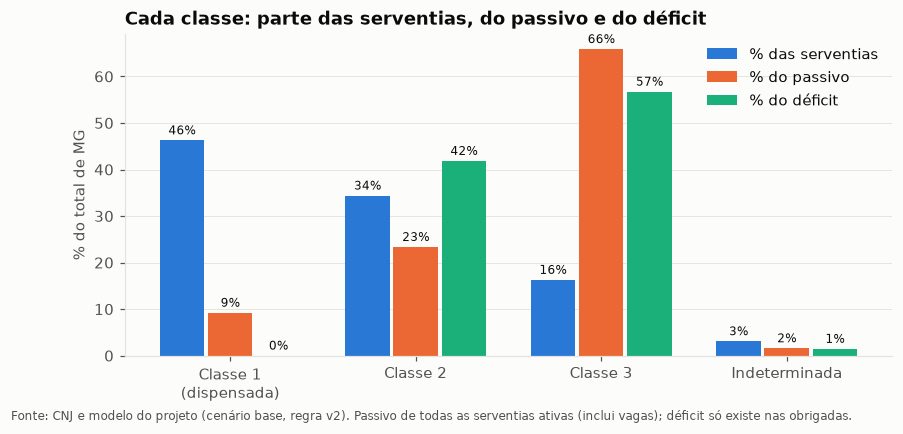

In [3]:
agg = dict(serventias=("cns", "size"), receita_mediana=("receita_ref", "median"), clt_mediano=("clt", "median"),
           clt=("clt", "sum"), passivo=("passivo", "sum"), obrigadas=("peso_universo", "sum"),
           passivo_obrigadas=("passivo_obrigadas", "sum"), com_deficit=("n_deficit", "sum"), deficit=("valor_descoberto", "sum"))
fmt_grupo = {"serventias": "int", "receita_mediana": "reais", "clt_mediano": "num1", "clt": "int", "passivo": "reais",
             "obrigadas": "num1", "passivo_obrigadas": "reais", "com_deficit": "num1", "deficit": "reais"}
por_classe = sv.groupby("classe").agg(**agg)
display(g.tabela(por_classe.reset_index(), fmt_grupo))
p_obr = por_classe.passivo_obrigadas / por_classe.passivo_obrigadas.sum()
print("Parte de cada classe no passivo de TODAS as serventias: "
      + "; ".join(f"{c}: {g.pct(v)}" for c, v in (por_classe.passivo / por_classe.passivo.sum()).items()))
print("Parte de cada classe no passivo das OBRIGADAS: " + "; ".join(f"{c}: {g.pct(v)}" for c, v in p_obr.items()))

part = pd.DataFrame({"serventias": por_classe.serventias / por_classe.serventias.sum(),
                     "passivo": por_classe.passivo / por_classe.passivo.sum(),
                     "déficit": por_classe.deficit / por_classe.deficit.sum()})
fig, ax = plt.subplots(figsize=(9, 3.8))
x = np.arange(len(part))
for i, (col, cor) in enumerate(zip(part.columns, g.CORES)):
    barras = ax.bar(x + (i - 1) * 0.26, 100 * part[col], width=0.24, color=cor, label=f"% das {col}" if col == "serventias" else f"% do {col}")
    ax.bar_label(barras, [g.pct(v, 0) for v in part[col]], fontsize=8, padding=2, color=g.TEXTO)
ax.set_xticks(x, ["Classe 1\n(dispensada)", "Classe 2", "Classe 3", "Indeterminada"])
ax.set_ylabel("% do total de MG")
ax.grid(axis="x", visible=False)
ax.legend(loc="upper right")
ax.set_title("Cada classe: parte das serventias, do passivo e do déficit")
g.nota(fig, "Fonte: CNJ e modelo do projeto (cenário base, regra v2). Passivo de todas as serventias ativas (inclui vagas); "
            "déficit só existe nas obrigadas.")
g.salvar(fig, "02_classe_serventias_passivo_deficit")
plt.show()

**Como ler.** Para cada classe, a barra azul é a % das serventias; a laranja, a % do passivo; a verde, a % do déficit. O passivo do gráfico é o de **todas as serventias ativas** (inclui vagas e outras, que ficam fora do universo).

**O que encontramos.**
- A **Classe 1** é quase metade das serventias (46%), mas só 9% do passivo: são cartórios pequenos (mediana de 1 CLT). Ela é dispensada do seguro, então não tem déficit no modelo.
- A **Classe 3** é só 16% das serventias, mas tem **66% do passivo de todas as serventias** e **57% do déficit**. Contando só o **passivo das obrigadas**, a parte dela sobe para **73%**. A mediana dela é de 12 CLT e R$ 3 milhões por semestre.
- A **Classe 2** tem 34% das serventias, 23% do passivo (26% do passivo das obrigadas) e **42% do déficit**: proporcionalmente, é a classe com mais déficit para o passivo que tem, porque o modelo supõe que uma parte maior das serventias médias não tem bens suficientes (premissas `prob_deficit` e `pct_descoberto` por faixa; D-011).

**O que significa para o Prov. 227.** O prêmio vem quase todo das Classes 2 e 3. A Classe 3 tem os contratos grandes; a Classe 2, muitos contratos médios com maior chance de déficit.

**Limitações.** As faixas de déficit são premissas do modelo (com fonte em `config/premissas/`), não observações; a divisão do déficit entre as classes depende delas.

## 3. Por situação: provida, vaga e outras

**A pergunta.** As serventias vagas são diferentes das providas?

**O método.** Mesmo agrupamento da seção 2, agora pela situação jurídica. O gráfico de caixa (*boxplot*) mostra a distribuição da receita: a caixa vai do Q1 ao Q3, o traço no meio é a mediana, e as "hastes" vão até as cercas de Tukey (1,5 × a altura da caixa; notebook 01).

,situacao,serventias,receita_mediana,clt_mediano,clt,passivo,obrigadas,passivo_obrigadas,com_deficit,deficit
0,provida,1.654,"R$ 518,8 mil","3,0",9.745,"R$ 254,6 mi","1.121,3","R$ 238,1 mi","486,0","R$ 36,9 mi"
1,vaga,830,"R$ 82,9 mil","1,0",2.105,"R$ 49,8 mi","0,0",R$ 0,"0,0",R$ 0
2,outras,41,"R$ 714,2 mil","4,0",284,"R$ 7,5 mi","0,0",R$ 0,"0,0",R$ 0


Vagas: 32,9% das serventias e 16,0% do passivo de MG.
Vagas de Classe 2 ou 3: 150 (18,1% das vagas), com R$ 35,4 mi de passivo; vagas com classe indeterminada: 48.


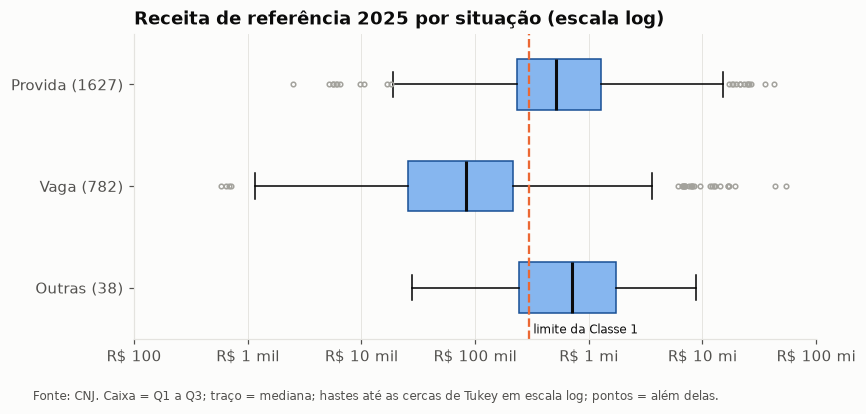

In [4]:
por_situacao = sv.groupby("situacao").agg(**agg).reindex(["provida", "vaga", "outras"])
display(g.tabela(por_situacao.reset_index(), fmt_grupo))
vagas = sv[sv.situacao == "vaga"]
vagas_acima = vagas[vagas.classe.isin(["2", "3"])]   # a indeterminada não entra: não sabemos a classe dela
print(f"Vagas: {g.pct(len(vagas) / len(sv))} das serventias e {g.pct(vagas.passivo.sum() / sv.passivo.sum())} do passivo de MG.")
print(f"Vagas de Classe 2 ou 3: {g.num(len(vagas_acima))} ({g.pct(len(vagas_acima) / len(vagas))} das vagas), com "
      f"{g.reais(vagas_acima.passivo.sum())} de passivo; vagas com classe indeterminada: {g.num(vagas.classe.eq('indeterminada').sum())}.")

fig, ax = plt.subplots(figsize=(8, 3.6))
grupos = [sv.loc[(sv.situacao == s) & (sv.receita_ref > 0), "receita_ref"] for s in ["provida", "vaga", "outras"]]
# a caixa é desenhada em log10, para as hastes seguirem as cercas de Tukey na escala log (como no notebook 01)
caixa = ax.boxplot([np.log10(x) for x in grupos], orientation="horizontal", widths=0.5, patch_artist=True, whis=1.5,
                   medianprops={"color": g.TEXTO, "linewidth": 2}, flierprops={"markersize": 3, "markeredgecolor": g.CINZA})
for p in caixa["boxes"]:
    p.set_facecolor(g.AZUL["claro"]); p.set_edgecolor(g.AZUL["escuro"])
limite = np.log10(enquadramento.limites_classe()[0])
ax.axvline(limite, color=g.CORES[1], linestyle="--", linewidth=1.5)
ax.text(limite, 3.45, " limite da Classe 1", color=g.TEXTO, fontsize=8)
ax.set_yticks([1, 2, 3], [f"Provida ({len(grupos[0])})", f"Vaga ({len(grupos[1])})", f"Outras ({len(grupos[2])})"])
ax.set_xticks(range(2, 9), [g.reais(10 ** t, 0) for t in range(2, 9)])
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_title("Receita de referência 2025 por situação (escala log)")
g.nota(fig, "Fonte: CNJ. Caixa = Q1 a Q3; traço = mediana; hastes até as cercas de Tukey em escala log; pontos = além delas.")
g.salvar(fig, "02_receita_por_situacao")
plt.show()

**Como ler.** Cada caixa mostra onde estão as serventias do meio de cada grupo; a linha laranja tracejada é o limite da Classe 1.

**O que encontramos.**
- As **vagas** são um terço das serventias (33%), mas com receita típica de **R$ 83 mil** por semestre, contra **R$ 519 mil** das providas: são muito menores. Mesmo assim, **150 vagas (18%) são Classe 2 ou 3**; outras 48 vagas têm classe indeterminada e não entram nessa conta. As vagas somam 16% do passivo de MG.
- As **providas** têm 82% do passivo, e **todo** o déficit do mercado vem delas (são as únicas no universo).
- As **outras** (41, sob intervenção ou em conversão em diligência) são poucas e ficam fora do universo.

**O que significa para o Prov. 227.** Se uma serventia vaga for provida por concurso, ela entra no universo (se não for Classe 1). As 150 vagas de Classe 2 ou 3 são, portanto, um **mercado futuro**: ≈ **R$ 35 milhões** de passivo que hoje está fora. A vacância também é um risco para a seguradora: quando a delegação termina (morte, aposentadoria, perda), o contrato precisa ser encerrado ou transferido (notebook 05).

**Limitações.** A situação é a do cadastro do CNJ em 17/10/2026; concursos em andamento não aparecem.

## 4. Por atribuição

**A pergunta.** Que tipo de cartório é maior e mais vezes obrigado?

**O método.** Uma serventia pode ter várias atribuições (por exemplo, Notas e Registro Civil juntos). Por isso cada serventia conta em **todas** as atribuições que tem, e as linhas não somam 2.525. Para cada atribuição: quantas serventias, receita mediana, % providas, % fora da Classe 1, passivo e obrigadas.

,atribuição,serventias,receita_mediana,providas,fora_da_classe_1,passivo,obrigadas,só_esta
2,Registro de imóveis (RI),329,"R$ 2,4 mi","84,2%","92,7%","R$ 116,6 mi","269,4","48,6%"
4,Pessoas jurídicas (RCPJ),292,"R$ 778,8 mil","83,9%","66,4%","R$ 34,2 mi","171,4","0,3%"
3,Títulos e documentos (RTD),290,"R$ 776,4 mil","84,1%","66,2%","R$ 32,8 mi","170,4","0,0%"
5,Protesto,305,"R$ 536,2 mil","90,8%","69,5%","R$ 34,7 mi","193,7","61,0%"
0,Notas,1.668,"R$ 238,4 mil","56,3%","42,4%","R$ 131,5 mi","625,9","22,7%"
1,Registro civil (RCPN),1.448,"R$ 163,1 mil","48,5%","29,4%","R$ 86,8 mi","362,9","14,5%"


,n_atribuicoes,serventias,receita_mediana,clt_mediano,clt,passivo,obrigadas,passivo_obrigadas,com_deficit,deficit
0,1,938,"R$ 730,0 mil","4,0",7.600,"R$ 217,1 mi","616,0","R$ 175,8 mi","258,7","R$ 25,4 mi"
1,2,1.365,"R$ 158,7 mil","2,0",3.013,"R$ 65,0 mi","335,1","R$ 38,1 mi","158,9","R$ 7,4 mi"
2,3,218,"R$ 1,3 mi","6,0",1.481,"R$ 28,7 mi","169,2","R$ 23,8 mi","67,9","R$ 4,0 mi"
3,4,2,"R$ 145,5 mil","5,5",11,"R$ 171,6 mil","0,0",R$ 0,"0,0",R$ 0
4,5,2,"R$ 1,1 mi","14,5",29,"R$ 925,5 mil","1,0","R$ 414,5 mil","0,5","R$ 103,6 mil"


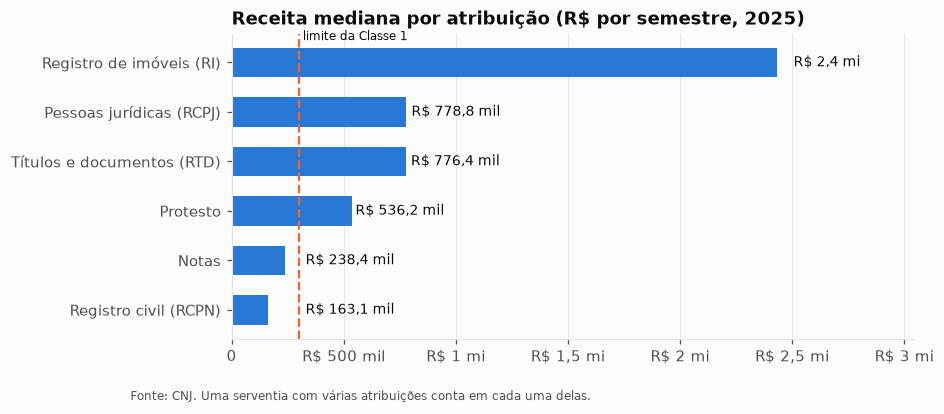

In [5]:
linhas = []
for a in dados.ATRIBUICOES:
    x = sv[sv[a]]
    linhas.append({"atribuição": dados.NOMES_ATRIBUICOES[a], "serventias": len(x), "receita_mediana": x.receita_ref.median(),
                   "providas": (x.situacao == "provida").mean(), "fora_da_classe_1": x.classe.isin(["2", "3"]).mean(),
                   "passivo": x.passivo.sum(), "obrigadas": x.peso_universo.sum(), "só_esta": (x.n_atribuicoes == 1).mean()})
por_atrib = pd.DataFrame(linhas).sort_values("receita_mediana", ascending=False)
display(g.tabela(por_atrib, {"serventias": "int", "receita_mediana": "reais", "providas": "pct", "fora_da_classe_1": "pct",
                             "passivo": "reais", "obrigadas": "num1", "só_esta": "pct"}))
display(g.tabela(sv.groupby("n_atribuicoes").agg(**agg).reset_index(), fmt_grupo))

fig, ax = plt.subplots(figsize=(8, 3.6))
r = por_atrib.sort_values("receita_mediana")
ax.barh(r["atribuição"], r["receita_mediana"], color=g.AZUL["medio"], height=0.6)
for i, v in enumerate(r["receita_mediana"]):   # o rótulo fica à direita da linha do limite, para não cruzá-la
    ax.text(max(v * 1.03, enquadramento.limites_classe()[0] * 1.1), i, g.reais(v), va="center", fontsize=9, color=g.TEXTO)
ax.axvline(enquadramento.limites_classe()[0], color=g.CORES[1], linestyle="--", linewidth=1.5)
ax.text(enquadramento.limites_classe()[0], 5.45, " limite da Classe 1", color=g.TEXTO, fontsize=8)
ax.set_xlim(0, r["receita_mediana"].max() * 1.25)
g.eixo_reais(ax, "x")
ax.grid(axis="y", visible=False)
ax.set_title("Receita mediana por atribuição (R$ por semestre, 2025)")
g.nota(fig, "Fonte: CNJ. Uma serventia com várias atribuições conta em cada uma delas.")
g.salvar(fig, "02_receita_mediana_por_atribuicao")
plt.show()

**Como ler.** Barras maiores = cartórios típicos maiores. A linha laranja é o limite da Classe 1: atribuições com a barra à esquerda dela têm a maioria das serventias dispensadas.

**O que encontramos.**
- O **Registro de Imóveis (RI)** é de longe o maior: receita mediana de **R$ 2,4 milhões** por semestre e **93%** fora da Classe 1. São só 329 serventias, mas com R$ 117 milhões de passivo.
- **Títulos e Documentos, Pessoas Jurídicas e Protesto** ficam em torno de R$ 540 mil a R$ 780 mil e cerca de dois terços fora da Classe 1.
- **Notas** e **Registro Civil** são as mais numerosas (1.668 e 1.448), mas com receita típica perto ou abaixo do limite (R$ 238 mil e R$ 163 mil): a maioria é Classe 1.
- O **número de atribuições** engana: as serventias com **2 atribuições** (54% do total, em geral Notas + Registro Civil no interior) são as **menores** (mediana de R$ 159 mil); as de **1 atribuição** (cartórios especializados nas cidades maiores) têm 70% do passivo.

**O que significa para o Prov. 227.** O cliente típico do seguro é um cartório de **Registro de Imóveis** ou especializado (Protesto, RTD/RCPJ) de cidade média ou grande. Os cartórios de Notas e Registro Civil do interior são, em maioria, dispensados.

**Limitações.** A receita é da serventia inteira, não de cada atribuição; numa serventia com várias atribuições não sabemos quanto vem de cada uma (o BI do CNJ separa por atribuição só a partir de 2025-2).

## 5. Por região intermediária do IBGE e mapa

**A pergunta.** Onde está o mercado em MG?

**O método.** Somamos por **região intermediária** do IBGE (13 regiões em MG, cada uma em torno de uma cidade-polo). No mapa, cada município é pintado pelo **passivo das obrigadas** (o passivo que entra no universo do Prov. 227), em faixas que crescem 10 vezes de uma para a outra. Os municípios **sem nenhuma obrigada** ficam em cinza; o município que tem obrigada, mas com passivo zero (zero CLT), fica em amarelo.

,regiao_intermediaria,serventias,receita_mediana,clt_mediano,clt,passivo,obrigadas,passivo_obrigadas,com_deficit,deficit,% do passivo das obrigadas,% das serventias
0,Belo Horizonte,324,"R$ 517,7 mil","3,0",3.027,"R$ 98,5 mi","176,0","R$ 85,0 mi","70,5","R$ 11,3 mi","35,7%","12,8%"
1,Uberlândia,87,"R$ 745,4 mil","3,0",785,"R$ 28,4 mi","47,4","R$ 22,1 mi","18,0","R$ 3,0 mi","9,3%","3,4%"
2,Divinópolis,185,"R$ 547,6 mil","3,0",934,"R$ 23,0 mi","111,4","R$ 18,8 mi","48,9","R$ 3,3 mi","7,9%","7,3%"
3,Varginha,249,"R$ 522,3 mil","3,0",1.153,"R$ 25,5 mi","135,4","R$ 18,5 mi","58,7","R$ 3,2 mi","7,8%","9,9%"
4,Pouso Alegre,215,"R$ 417,5 mil","3,0",892,"R$ 19,9 mi","122,7","R$ 15,4 mi","55,7","R$ 2,8 mi","6,5%","8,5%"
5,Patos de Minas,133,"R$ 506,8 mil","3,0",641,"R$ 18,2 mi","71,7","R$ 14,3 mi","30,2","R$ 2,3 mi","6,0%","5,3%"
6,Uberaba,89,"R$ 626,0 mil","3,0",607,"R$ 21,1 mi","53,4","R$ 14,3 mi","22,3","R$ 2,1 mi","6,0%","3,5%"
7,Juiz de Fora,407,"R$ 209,9 mil","2,0",1.307,"R$ 23,5 mi","132,7","R$ 13,2 mi","59,6","R$ 2,4 mi","5,5%","16,1%"
8,Montes Claros,214,"R$ 129,9 mil","2,0",778,"R$ 15,3 mi","68,4","R$ 11,5 mi","31,2","R$ 2,0 mi","4,8%","8,5%"
9,Barbacena,128,"R$ 256,3 mil","2,0",446,"R$ 10,3 mi","52,7","R$ 7,2 mi","23,4","R$ 1,3 mi","3,0%","5,1%"


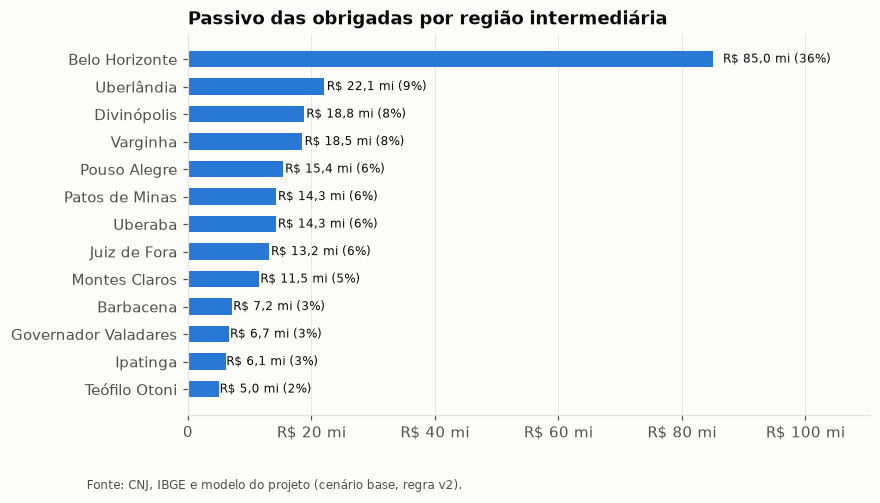

In [6]:
por_regiao = sv.groupby("regiao_intermediaria").agg(**agg).sort_values("passivo_obrigadas", ascending=False)
por_regiao["% do passivo das obrigadas"] = por_regiao.passivo_obrigadas / por_regiao.passivo_obrigadas.sum()
por_regiao["% das serventias"] = por_regiao.serventias / por_regiao.serventias.sum()
display(g.tabela(por_regiao.reset_index(), fmt_grupo | {"% do passivo das obrigadas": "pct", "% das serventias": "pct"}))

fig, ax = plt.subplots(figsize=(8, 4.5))
r = por_regiao.sort_values("passivo_obrigadas")
ax.barh(r.index, r.passivo_obrigadas, color=g.AZUL["medio"], height=0.6)
for i, (v, p) in enumerate(zip(r.passivo_obrigadas, r["% do passivo das obrigadas"])):
    ax.text(v * 1.02, i, f"{g.reais(v)} ({g.pct(p, 0)})", va="center", fontsize=8, color=g.TEXTO)
ax.set_xlim(0, r.passivo_obrigadas.max() * 1.3)
g.eixo_reais(ax, "x")
ax.grid(axis="y", visible=False)
ax.set_title("Passivo das obrigadas por região intermediária")
g.nota(fig, "Fonte: CNJ, IBGE e modelo do projeto (cenário base, regra v2).")
g.salvar(fig, "02_passivo_obrigadas_por_regiao_intermediaria")
plt.show()

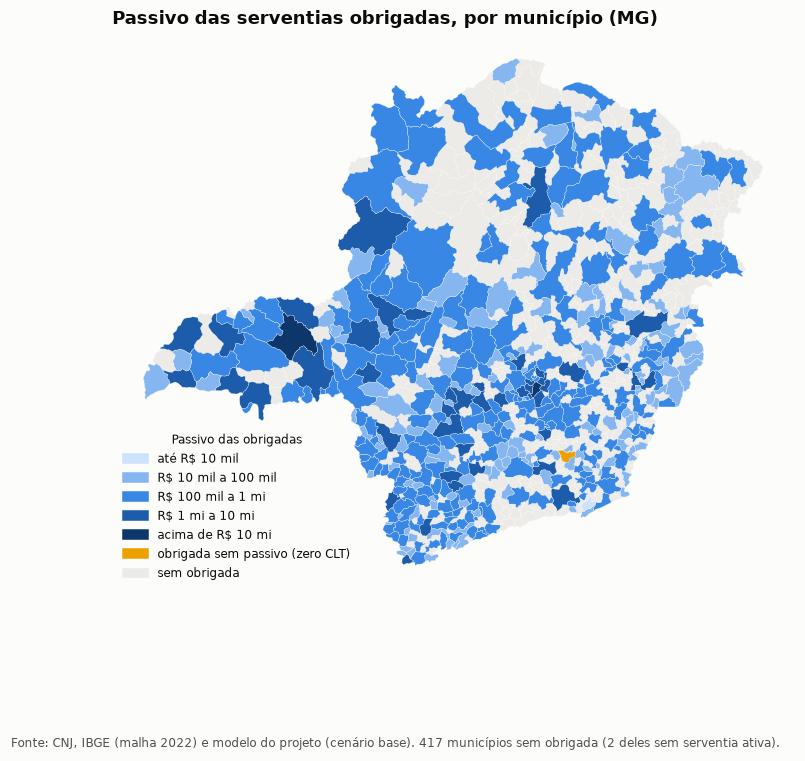

Municípios de MG: 853. Com alguma obrigada: 436 (435 com passivo e 1 com obrigada de passivo zero). Sem obrigada: 417, dos quais 2 sem serventia ativa.


In [7]:
por_mun = sv.groupby("cod_ibge").agg(obrigadas=("peso_universo", "sum"), passivo_obrigadas=("passivo_obrigadas", "sum"))
mapa = dados.malha(con).merge(por_mun.reset_index(), on="cod_ibge", how="left")
mapa["sem_serventia"] = mapa["obrigadas"].isna()
mapa[["obrigadas", "passivo_obrigadas"]] = mapa[["obrigadas", "passivo_obrigadas"]].fillna(0)
sem_obrigada = mapa.obrigadas == 0
obrigada_sem_passivo = (mapa.obrigadas > 0) & (mapa.passivo_obrigadas == 0)   # obrigada com zero CLT
com_passivo = mapa.passivo_obrigadas > 0
faixas = [0, 1e4, 1e5, 1e6, 1e7, 1e9]
rotulos = ["até R$ 10 mil", "R$ 10 mil a 100 mil", "R$ 100 mil a 1 mi", "R$ 1 mi a 10 mi", "acima de R$ 10 mi"]
cores = ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]
CINZA_MAPA, AMARELO = "#ecebe7", g.CORES[3]
fig, ax = plt.subplots(figsize=(8, 7.5))
mapa[sem_obrigada].plot(ax=ax, color=CINZA_MAPA, edgecolor=g.SUPERFICIE, linewidth=0.2)
mapa[obrigada_sem_passivo].plot(ax=ax, color=AMARELO, edgecolor=g.SUPERFICIE, linewidth=0.2)
mapa[com_passivo].plot(ax=ax, column="passivo_obrigadas", cmap=ListedColormap(cores),
                       norm=BoundaryNorm(faixas, len(cores)), edgecolor=g.SUPERFICIE, linewidth=0.2)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=c, label=r) for c, r in zip(cores, rotulos)]
          + [Patch(color=AMARELO, label="obrigada sem passivo (zero CLT)"), Patch(color=CINZA_MAPA, label="sem obrigada")],
          loc="lower left", fontsize=8, title="Passivo das obrigadas", title_fontsize=8)
ax.set_axis_off()
ax.set_title("Passivo das serventias obrigadas, por município (MG)")
g.nota(fig, f"Fonte: CNJ, IBGE (malha 2022) e modelo do projeto (cenário base). {int(sem_obrigada.sum())} municípios sem "
            f"obrigada ({int(mapa.sem_serventia.sum())} deles sem serventia ativa).")
g.salvar(fig, "02_mapa_passivo_obrigadas_por_municipio")
plt.show()
print(f"Municípios de MG: {len(mapa)}. Com alguma obrigada: {g.num((mapa.obrigadas > 0).sum())} "
      f"({g.num(com_passivo.sum())} com passivo e {g.num(obrigada_sem_passivo.sum())} com obrigada de passivo zero). "
      f"Sem obrigada: {g.num(sem_obrigada.sum())}, dos quais {g.num(mapa.sem_serventia.sum())} sem serventia ativa.")

**Como ler.** Na tabela e nas barras, as regiões estão ordenadas pelo passivo das obrigadas. No mapa, quanto mais escuro o município, mais passivo obrigado ele tem.

**O que encontramos.**
- A região de **Belo Horizonte** concentra **36%** do passivo das obrigadas, com 13% das serventias.
- As regiões do **Triângulo** (Uberlândia e Uberaba) têm poucas serventias (3% a 4% cada), mas de porte grande: a receita mediana é a mais alta de MG.
- O **Norte e o Leste** (Montes Claros, Teófilo Otoni, Governador Valadares, Ipatinga) têm muitas serventias pequenas e pouco passivo obrigado.
- Dos 853 municípios, **436 têm alguma obrigada** e **417 não têm nenhuma** (cinza): neles, as serventias são Classe 1, vagas ou em situação especial; 2 desses 417 nem têm serventia ativa. Dos 436, um tem obrigada com passivo zero (amarelo).

**O que significa para o Prov. 227.** Uma seguradora que atenda a região metropolitana de BH e o Triângulo cobre a maior parte do mercado de MG com poucos clientes; o resto do estado é pulverizado.

**Limitações.** O passivo é atribuído ao município da serventia; a distribuição de salários usada no modelo é a do município, da região imediata ou de MG (D-022), conforme o número de vínculos.

## 6. Série histórica da arrecadação (2007 a 2026-1)

**A pergunta.** Como a arrecadação dos cartórios de MG evoluiu, em valores correntes e descontada a inflação?

**O método.**
- **Valor nominal**: o que foi declarado em cada semestre.
- **Valor real**: o nominal corrigido pela inflação (IPCA do IBGE), a **preços de dezembro de 2025**. Exemplo: se os preços subiram 10% entre um semestre e dez/2025, R$ 100 daquele semestre valem R$ 110 de dez/2025. O fator de cada semestre é o índice de dez/2025 ÷ a média do índice nos 6 meses do semestre. O IPCA no banco começa em jan/2019, então a série real vai de 2019 a 2025.
- **Série sem saltos**: os saltos grosseiros do notebook 01 (semestres 10 vezes acima ou abaixo do histórico da serventia) trocados pela mediana anterior, para ver quanto eles pesam no total. É só uma conferência, não a série oficial.
- **Taxa média de crescimento por ano**, comparando sempre o mesmo semestre (1º com 1º), porque o 2º semestre arrecada mais todo ano. Duas formas de calcular:
  - **ponta a ponta**: (valor final ÷ valor inicial)^(1 ÷ número de anos) − 1. Exemplo: de 100 para 121 em 2 anos → (1,21)^(1/2) − 1 = 10% ao ano. Só olha o primeiro e o último ano, então depende muito de quais anos escolhemos;
  - **reta de tendência**: ajusta uma reta ao logaritmo dos valores de todos os anos e lê a inclinação. Usa todos os pontos, então um ano atípico na ponta (como a pandemia em 2020) pesa menos.
- Como nenhuma conta sozinha é "a" taxa, mostramos várias e apresentamos o resultado como uma **faixa**.

,periodo,nominal,nominal_sem_saltos,real,real_sem_saltos,peso_dos_saltos
0,2020-2,"R$ 1,4 bi","R$ 1,4 bi","R$ 1,9 bi","R$ 1,9 bi","-0,0%"
1,2021-1,"R$ 1,4 bi","R$ 1,4 bi","R$ 1,8 bi","R$ 1,8 bi","0,0%"
2,2021-2,"R$ 1,7 bi","R$ 1,7 bi","R$ 2,1 bi","R$ 2,1 bi","0,1%"
3,2022-1,"R$ 1,7 bi","R$ 1,7 bi","R$ 2,0 bi","R$ 2,0 bi","-0,0%"
4,2022-2,"R$ 2,0 bi","R$ 2,0 bi","R$ 2,3 bi","R$ 2,3 bi","-0,0%"
5,2023-1,"R$ 1,8 bi","R$ 1,8 bi","R$ 2,1 bi","R$ 2,1 bi","-0,0%"
6,2023-2,"R$ 2,2 bi","R$ 2,2 bi","R$ 2,4 bi","R$ 2,4 bi","-0,0%"
7,2024-1,"R$ 2,0 bi","R$ 2,0 bi","R$ 2,2 bi","R$ 2,2 bi","0,1%"
8,2024-2,"R$ 2,5 bi","R$ 2,5 bi","R$ 2,6 bi","R$ 2,6 bi","0,7%"
9,2025-1,"R$ 2,4 bi","R$ 2,4 bi","R$ 2,4 bi","R$ 2,4 bi","0,2%"


,"conta (valores reais, 1º semestres)",crescimento ao ano
0,"Ponta a ponta, 2019-1 → 2025-1 (todas)","8,2%"
1,"Reta de tendência, 1º semestres de 2019 a 2025","9,7%"
2,"Ponta a ponta, 2021-1 → 2025-1","7,9%"
3,"Ponta a ponta, 2022-1 → 2025-1","6,5%"
4,Mesmas serventias nas duas pontas (2.372),"8,0%"
5,"Mesmas serventias, sem mudanças de mais de 10×...","7,8%"
6,"Série sem os saltos, 2019-1 → 2025-1","8,2%"


Nominal, 2019-1 → 2025-1: 14,5% ao ano; IPCA no período: 5,7% ao ano.
2º semestres, 2019-2 → 2025-2: real 10,5%, real sem saltos 9,5%.
2026-1 sobre 2025-1: nominal 34,6%; sem saltos 20,9%.
2º semestre sobre o 1º do mesmo ano (mediana 2010 a 2024): 16,1%.


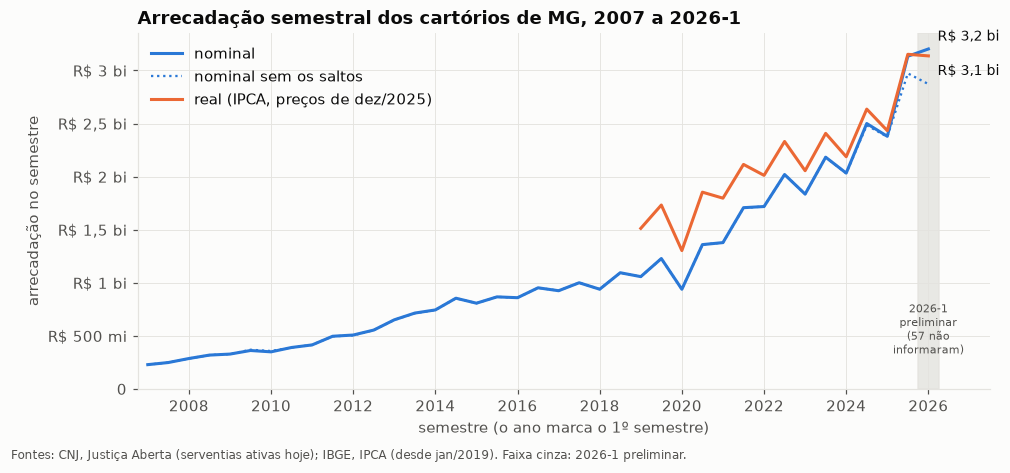

In [8]:
saltos = est.saltos(ar)
total = pd.DataFrame({"nominal": ar.groupby("periodo").arrecadacao.sum(),
                      "nominal_sem_saltos": est.sem_saltos(ar, saltos).groupby("periodo").arrecadacao.sum()})
fator = est.fatores_reais(dados.indice_preco(con, "IPCA"), 202512)
total["real"] = total["nominal"] * fator
total["real_sem_saltos"] = total["nominal_sem_saltos"] * fator
total["peso_dos_saltos"] = total["nominal"] / total["nominal_sem_saltos"] - 1
display(g.tabela(total.tail(12).reset_index(), {"nominal": "reais", "nominal_sem_saltos": "reais", "real": "reais",
                                                "real_sem_saltos": "reais", "peso_dos_saltos": "pct"}))


def mesmo_semestre(col: str, semestre: int = 1, de: int = 2019, ate: int = 2025) -> pd.Series:
    """Um valor por ano, sempre do mesmo semestre (o 2º arrecada mais todo ano): a taxa sai "por ano"."""
    return total.loc[[f"{a}-{semestre}" for a in range(de, ate + 1)], col]


# as mesmas serventias nas duas pontas (valor > 0 em 2019-1 e em 2025-1): tira o efeito de quem entrou ou zerou
largura = ar.pivot_table(index="cns", columns="periodo", values="arrecadacao")
mesmas = largura[(largura["2019-1"] > 0) & (largura["2025-1"] > 0)]
razao = mesmas["2025-1"] / mesmas["2019-1"]
sem_extremos = mesmas[(razao > 0.1) & (razao < 10)]   # tira quem mudou mais de 10 vezes no período
pontas_reais = lambda df: pd.Series([df["2019-1"].sum() * fator["2019-1"], df["2025-1"].sum() * fator["2025-1"]])
taxas = pd.DataFrame([
    ("Ponta a ponta, 2019-1 → 2025-1 (todas)", est.crescimento_medio(mesmo_semestre("real"))),
    ("Reta de tendência, 1º semestres de 2019 a 2025", est.crescimento_tendencia(mesmo_semestre("real"))),
    ("Ponta a ponta, 2021-1 → 2025-1", est.crescimento_medio(mesmo_semestre("real", de=2021))),
    ("Ponta a ponta, 2022-1 → 2025-1", est.crescimento_medio(mesmo_semestre("real", de=2022))),
    (f"Mesmas serventias nas duas pontas ({g.num(len(mesmas))})", est.crescimento_medio(pontas_reais(mesmas), periodos=6)),
    (f"Mesmas serventias, sem mudanças de mais de 10× ({g.num(len(sem_extremos))})",
     est.crescimento_medio(pontas_reais(sem_extremos), periodos=6)),
    ("Série sem os saltos, 2019-1 → 2025-1", est.crescimento_medio(mesmo_semestre("real_sem_saltos"))),
], columns=["conta (valores reais, 1º semestres)", "crescimento ao ano"])
display(g.tabela(taxas, {"crescimento ao ano": "pct"}))

ipca = est.crescimento_medio(1 / mesmo_semestre("real").div(mesmo_semestre("nominal")))   # 1/fator = nível de preços
print(f"Nominal, 2019-1 → 2025-1: {g.pct(est.crescimento_medio(mesmo_semestre('nominal')))} ao ano; "
      f"IPCA no período: {g.pct(ipca)} ao ano.")
print(f"2º semestres, 2019-2 → 2025-2: real {g.pct(est.crescimento_medio(mesmo_semestre('real', 2)))}, "
      f"real sem saltos {g.pct(est.crescimento_medio(mesmo_semestre('real_sem_saltos', 2)))}.")
print(f"2026-1 sobre 2025-1: nominal {g.pct(total.loc['2026-1', 'nominal'] / total.loc['2025-1', 'nominal'] - 1)}; "
      f"sem saltos {g.pct(total.loc['2026-1', 'nominal_sem_saltos'] / total.loc['2025-1', 'nominal_sem_saltos'] - 1)}.")
print(f"2º semestre sobre o 1º do mesmo ano (mediana 2010 a 2024): "
      f"{g.pct(np.median([total.loc[f'{a}-2', 'nominal'] / total.loc[f'{a}-1', 'nominal'] - 1 for a in range(2010, 2025)]))}.")
nao_informado_2026 = int((~ar.loc[ar.periodo == "2026-1", "informado"]).sum())

fig, ax = plt.subplots(figsize=(10, 4.2))
x = np.arange(len(total))
ax.plot(x, total.nominal, color=g.CORES[0], label="nominal")
ax.plot(x, total.nominal_sem_saltos, color=g.CORES[0], linestyle=":", linewidth=1.5, label="nominal sem os saltos")
ax.plot(x, total.real, color=g.CORES[1], label="real (IPCA, preços de dez/2025)")
for col, dy in (("nominal", 8), ("real", -10)):
    ax.annotate(g.reais(total[col].dropna().iloc[-1]), (x[total[col].notna()][-1], total[col].dropna().iloc[-1]),
                xytext=(6, dy), textcoords="offset points", fontsize=9, color=g.TEXTO, va="center")
ax.axvspan(x[-1] - 0.5, x[-1] + 0.5, color=g.GRADE, alpha=0.8, zorder=0)   # 2026-1: semestre ainda incompleto na fonte
ax.text(x[-1], 300e6, f"2026-1\npreliminar\n({nao_informado_2026} não\ninformaram)", ha="center", va="bottom",
        fontsize=7, color=g.TEXTO_2)
g.eixo_periodos(ax, list(total.index))
ax.set_xlim(-0.5, len(x) + 2)
g.eixo_reais(ax)
ax.set_ylim(0, None)
ax.set_xlabel("semestre (o ano marca o 1º semestre)")
ax.set_ylabel("arrecadação no semestre")
ax.legend(loc="upper left")
ax.set_title("Arrecadação semestral dos cartórios de MG, 2007 a 2026-1")
g.nota(fig, "Fontes: CNJ, Justiça Aberta (serventias ativas hoje); IBGE, IPCA (desde jan/2019). "
            "Faixa cinza: 2026-1 preliminar.")
g.salvar(fig, "02_serie_arrecadacao_mg")
plt.show()

Agora, **por classe**. Para comparar classes de tamanhos muito diferentes no mesmo eixo, usamos um **índice**: o valor de cada semestre dividido pelo do 1º semestre de 2019, vezes 100 (2019-1 = 100; 150 quer dizer "50% acima de 2019-1"). A classe é a **atual** (2025) de cada serventia; usamos a série sem saltos e só os 1º semestres, para tirar o efeito sazonal.

classe,ano,1,2,3,indeterminada
0,2019,"100,0","100,0","100,0","100,0"
1,2020,"84,5","87,8","89,4","86,4"
2,2021,"129,4","129,0","130,9","118,2"
3,2022,"154,4","159,3","164,3","138,4"
4,2023,"167,7","170,5","174,8","182,6"
5,2024,"183,3","187,7","194,5","135,6"
6,2025,"201,4","217,7","230,3","32,5"
7,2026,"259,1","273,8","272,1","231,2"


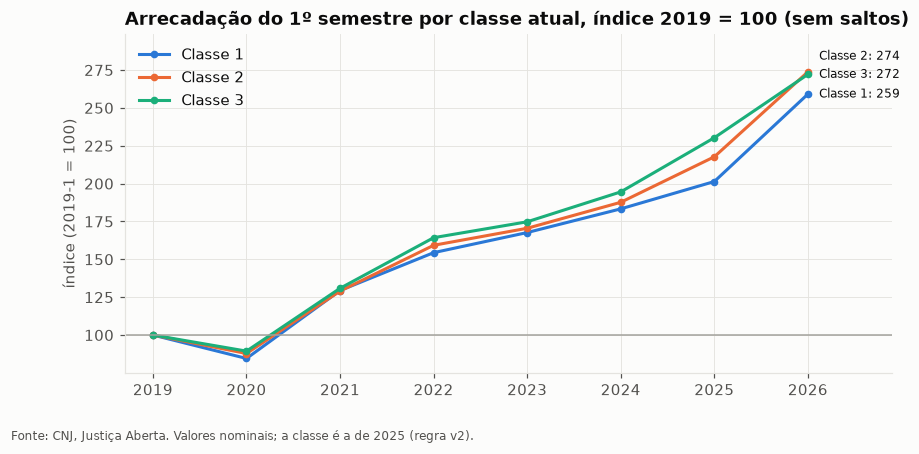

In [9]:
sem = est.sem_saltos(ar, saltos).merge(sv[["cns", "classe"]], on="cns")
s1 = sem[(sem.semestre == 1) & (sem.ano >= 2019)].groupby(["ano", "classe"]).arrecadacao.sum().unstack()
indice = 100 * s1 / s1.iloc[0]
display(g.tabela(indice.reset_index(), {c: "num1" for c in indice.columns}))

fig, ax = plt.subplots(figsize=(9, 4))
nomes = {"1": "Classe 1", "2": "Classe 2", "3": "Classe 3", "indeterminada": "Indeterminada"}
classes = ["1", "2", "3"]   # a indeterminada fica só na tabela: ela zera em 2025 por definição (notebook 01)
fim = indice[classes].iloc[-1].sort_values()
posicao = {c: v for c, v in zip(fim.index, np.maximum.accumulate(fim.values - 12 * np.arange(3)) + 12 * np.arange(3))}
for i, c in enumerate(classes):
    ax.plot(indice.index, indice[c], color=g.CORES[i], marker="o", markersize=4, label=nomes[c])
    ax.annotate(f"{nomes[c]}: {g.num(indice[c].iloc[-1])}", (indice.index[-1], indice[c].iloc[-1]),
                xytext=(indice.index[-1] + 0.12, posicao[c]), textcoords="data", fontsize=8, color=g.TEXTO, va="center")
ax.axhline(100, color=g.CINZA, linewidth=1)
ax.set_xlim(2018.7, 2026.9)
ax.set_ylim(None, indice[classes].values.max() + 25)
ax.set_ylabel("índice (2019-1 = 100)")
ax.legend(loc="upper left")
ax.set_title("Arrecadação do 1º semestre por classe atual, índice 2019 = 100 (sem saltos)")
g.nota(fig, "Fonte: CNJ, Justiça Aberta. Valores nominais; a classe é a de 2025 (regra v2).")
g.salvar(fig, "02_serie_arrecadacao_por_classe_indice")
plt.show()

**Ilustração: quantas serventias passam do limite a cada ano?** Para cada ano, a média dos dois semestres de cada serventia, comparada com o limite de R$ 300 mil. **É só uma ilustração**, com três simplificações:
- o limite **atual** é aplicado ao passado (em 2007 ele não existia);
- só entram as serventias **ativas hoje**, com a situação **atual** (uma provida hoje pode ter sido vaga em 2007);
- usa a média simples dos semestres, **com os zeros** (não reproduz a regra do painel).

Para separar o efeito da inflação, a partir de 2019 contamos também as providas acima do limite **corrigido pelo IPCA**: os R$ 300 mil de 2025 levados aos preços de cada ano (em 2019, ≈ R$ 214 mil).

ano,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
situacao,,,,,,,,,,,,,,,,,,,
outras,4,5,5,6,6,7,7,7,8,9,12,12,13,12,16,19,20,23,25
provida,112,153,192,216,278,312,372,406,437,474,514,532,589,615,758,845,899,988,1087
vaga,34,38,41,42,49,57,62,69,76,78,82,84,91,86,104,125,138,132,150
total,150,196,238,264,333,376,441,482,521,561,608,628,693,713,878,989,1057,1143,1262


,ano,limite corrigido (R$),providas acima (limite fixo),providas acima (limite corrigido)
0,2019,"R$ 214,2 mil",589,756
1,2020,"R$ 221,1 mil",615,746
2,2021,"R$ 239,3 mil",758,870
3,2022,"R$ 261,7 mil",845,923
4,2023,"R$ 273,7 mil",899,948
5,2024,"R$ 285,7 mil",988,1016
6,2025,"R$ 300,0 mil",1087,1087


Providas acima do limite, 2019 → 2025: +498 com o limite fixo e +331 com o limite corrigido; a diferença (34% do aumento) é só a inflação.


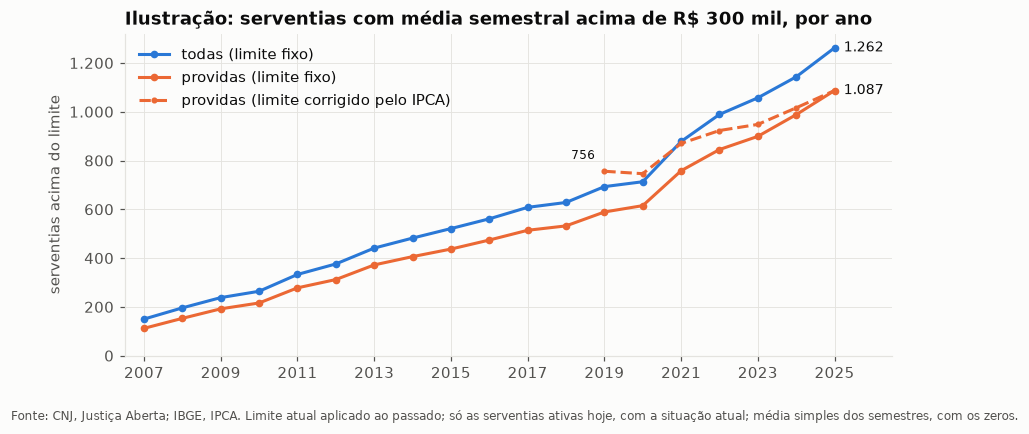

In [10]:
limite = enquadramento.limites_classe()[0]
anual = ar[ar.ano <= 2025].groupby(["cns", "ano"]).arrecadacao.mean().reset_index().merge(sv[["cns", "situacao"]], on="cns")
anual["acima"] = anual.arrecadacao > limite
acima = anual[anual.acima].groupby(["ano", "situacao"]).size().unstack(fill_value=0)
acima["total"] = acima.sum(axis=1)
display(acima.T)

# limite corrigido pelo IPCA: o mesmo R$ 300 mil de 2025 levado aos preços de cada ano (só desde 2019, por causa do IPCA)
fator_ano = fator.groupby(lambda p: int(p[:4])).mean()
limite_corrigido = (limite * fator_ano[2025] / fator_ano).loc[2019:2025]
providas = anual[anual.situacao == "provida"]
acima_corrigido = pd.Series({a: int((providas[providas.ano == a].arrecadacao > l).sum()) for a, l in limite_corrigido.items()})
comparacao = pd.DataFrame({"limite corrigido (R$)": limite_corrigido, "providas acima (limite fixo)": acima.provida.loc[2019:2025],
                           "providas acima (limite corrigido)": acima_corrigido})
display(g.tabela(comparacao.reset_index(names="ano"), {"limite corrigido (R$)": "reais"}))
aumento_fixo = acima.provida[2025] - acima.provida[2019]
aumento_corrigido = acima_corrigido[2025] - acima_corrigido[2019]
print(f"Providas acima do limite, 2019 → 2025: +{g.num(aumento_fixo)} com o limite fixo e +{g.num(aumento_corrigido)} com o "
      f"limite corrigido; a diferença ({g.pct(1 - aumento_corrigido / aumento_fixo, 0)} do aumento) é só a inflação.")

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(acima.index, acima.total, color=g.CORES[0], marker="o", markersize=4, label="todas (limite fixo)")
ax.plot(acima.index, acima.provida, color=g.CORES[1], marker="o", markersize=4, label="providas (limite fixo)")
ax.plot(acima_corrigido.index, acima_corrigido.values, color=g.CORES[1], linestyle="--", marker="o", markersize=3,
        label="providas (limite corrigido pelo IPCA)")
for serie in (acima.total, acima.provida):
    ax.annotate(g.num(serie.iloc[-1]), (serie.index[-1], serie.iloc[-1]), xytext=(6, 0),
                textcoords="offset points", fontsize=9, color=g.TEXTO, va="center")
ax.annotate(g.num(acima_corrigido[2019]), (2019, acima_corrigido[2019]), xytext=(-6, 8), textcoords="offset points",
            fontsize=8, color=g.TEXTO, ha="right")
g.eixo_num(ax)
ax.set_ylim(0, None)
ax.set_xlim(2006.5, 2026.5)
ax.set_xticks(range(2007, 2026, 2))
ax.set_ylabel("serventias acima do limite")
ax.legend(loc="upper left")
ax.set_title("Ilustração: serventias com média semestral acima de R$ 300 mil, por ano")
g.nota(fig, "Fonte: CNJ, Justiça Aberta; IBGE, IPCA. Limite atual aplicado ao passado; só as serventias ativas hoje, "
            "com a situação atual; média simples dos semestres, com os zeros.")
g.salvar(fig, "02_serventias_acima_do_limite_por_ano")
plt.show()

**Como ler.** No primeiro gráfico, a linha azul é o total declarado; a pontilhada, o mesmo total sem os saltos grosseiros; a laranja, o total a preços de dez/2025; a faixa cinza marca 2026-1, ainda incompleto. No segundo, cada linha é uma classe e o ponto de partida é 100. No terceiro, quantas serventias passariam do limite a cada ano; a linha tracejada usa o limite corrigido pela inflação.

**O que encontramos.**
- A arrecadação de MG cresce **≈ 7% a 10% ao ano acima do IPCA** (2019 a 2025, 1º semestres). A conta ponta a ponta dá **8,2%**; pela reta de tendência, **9,7%**; começando em 2022, **6,5%**. Em valor nominal, 14,5% ao ano, com IPCA de 5,7% ao ano no período. O 2º semestre arrecada, todo ano, mais que o 1º (mediana de 16% a mais, 2010 a 2024).
- **Os saltos do notebook 01 não explicam esse crescimento**: com as mesmas 2.372 serventias nas duas pontas, a taxa é 8,0%; tirando também quem mudou mais de 10 vezes, 7,8%; na série sem saltos, 8,2%. Nos 2º semestres, os saltos pesam mais (10,5% com eles, 9,5% sem), por causa de 2025-2.
- A pandemia aparece em **2020-1** (queda forte, recuperada no semestre seguinte).
- **2025-2 e 2026-1 saltam**: +25% e +35% sobre o mesmo semestre do ano anterior, em valor nominal. Parte disso são os **saltos individuais** do notebook 01: eles respondem por 5,4% do total de 2025-2 e **11,5% do total de 2026-1**. Sem eles, 2026-1 cresce 21% sobre 2025-1, ainda acima dos anos anteriores. O resto pode ser efeito de reajustes de emolumentos ou do mercado imobiliário (hipóteses, não testadas aqui). 2026-1 ainda é **preliminar** (57 serventias não informaram).
- **Por classe**, as Classes 2 e 3 crescem um pouco mais rápido que a Classe 1 (índice de 218 e 230 em 2025, contra 201), mas veja a limitação abaixo.
- **Ilustração do limite:** com o limite fixo, as providas acima de R$ 300 mil passam de 112 em 2007 para **1.087 em 2025**. De 2019 a 2025, o aumento é de **+498** com o limite fixo e de **+331** com o limite corrigido pelo IPCA (756 → 1.087): cerca de **1/3 do aumento (34%) é só a inflação** passando a régua; os outros 2/3 vêm do crescimento real da arrecadação.

**O que significa para o Prov. 227.** Com o limite fixo, o universo de obrigadas tende a **crescer sozinho**, por dois motivos: a inflação (cerca de 1/3 do efeito) e o crescimento real da arrecadação (cerca de 2/3). Se o limite for corrigido pela inflação (art. 16, §2º, do Prov. 213), sobra só a segunda parte: o crescimento fica menor, mas continua. É a base da previsão do notebook 07, que precisa tratar com cuidado os saltos de 2025-2 e 2026-1.

**Limitações.** A série inclui só as serventias **ativas hoje** (as extintas faltam no passado), e a classe e a situação são as **atuais**, aplicadas para trás. Isso cria um viés no índice por classe: quem cresceu mais até 2025 tem mais chance de estar hoje na Classe 3, então parte da "vantagem" das classes maiores vem da própria forma de agrupar. A série real só começa em 2019 (o IPCA do banco começa ali). A contagem acima do limite é uma ilustração (ver acima) e não reproduz a regra do painel.

## 7. Correlações: o que anda junto

**A pergunta.** Receita, empregados, número de atribuições, passivo e o tamanho da cidade andam juntos?

**O método.** **Correlação de Spearman** (notebook 01, seção 8): vai de −1 a +1 e usa a posição de cada serventia na fila, não o valor. Assim, os grandes cartórios não dominam a conta. Leitura comum: acima de 0,7 em módulo, relação forte; entre 0,4 e 0,7, moderada; abaixo de 0,4, fraca. Exemplo: se as 3 serventias que mais arrecadam são também as 3 com mais empregados, na mesma ordem, a correlação é +1.

Uma correlação **não** prova causa: só diz que as duas medidas sobem (ou descem) juntas.

b,CLT,nº atribuições,passivo,população do município
a,,,,
receita,"0,83","-0,29","0,82","0,45"
CLT,,"-0,21","0,95","0,43"
nº atribuições,,,"-0,23","-0,41"
passivo,,,,"0,44"


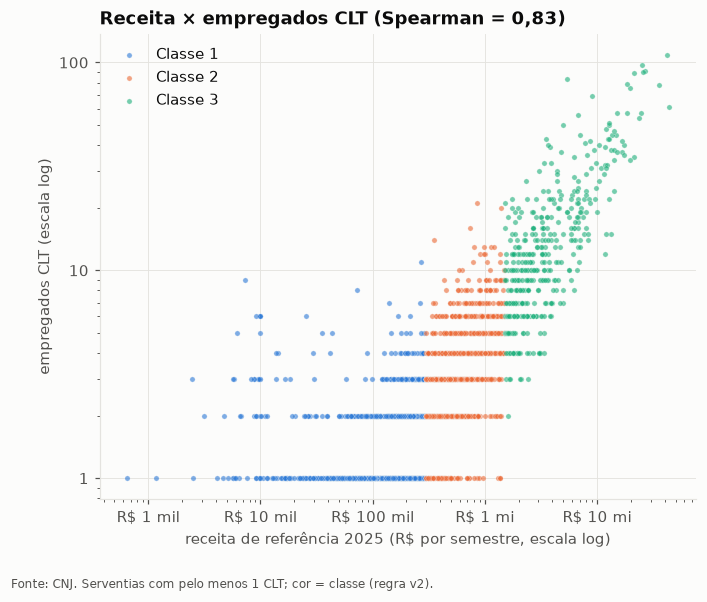

In [11]:
cols = {"receita_ref": "receita", "clt": "CLT", "n_atribuicoes": "nº atribuições", "passivo": "passivo", "populacao": "população do município"}
corr = est.correlacoes(sv, list(cols))
matriz = corr.pivot(index="a", columns="b", values="rho").reindex(index=list(cols)[:-1], columns=list(cols)[1:])
matriz = matriz.rename(index=cols, columns=cols)
display(matriz.map(lambda v: "" if pd.isna(v) else g.num(v, 2)))

fig, ax = plt.subplots(figsize=(7, 5.5))
for i, (c, nome) in enumerate([("1", "Classe 1"), ("2", "Classe 2"), ("3", "Classe 3")]):
    x = sv[(sv.classe == c) & (sv.clt > 0)]
    ax.scatter(x.receita_ref, x.clt, s=12, color=g.CORES[i], alpha=0.6, edgecolor=g.SUPERFICIE, linewidth=0.3, label=nome)
ax.set_xscale("log"); ax.set_yscale("log")
g.eixo_reais(ax, "x"); g.eixo_num(ax, "y")
ax.set_xlabel("receita de referência 2025 (R$ por semestre, escala log)")
ax.set_ylabel("empregados CLT (escala log)")
ax.legend(loc="upper left")
rho = corr.set_index(["a", "b"]).rho[("receita_ref", "clt")]
ax.set_title(f"Receita × empregados CLT (Spearman = {g.num(rho, 2)})")
g.nota(fig, "Fonte: CNJ. Serventias com pelo menos 1 CLT; cor = classe (regra v2).")
g.salvar(fig, "02_receita_x_clt_por_classe")
plt.show()

**Como ler.** Na tabela, cada número é a correlação entre a linha e a coluna. No gráfico, cada ponto é uma serventia: quanto mais à direita, mais receita; quanto mais alto, mais empregados.

**O que encontramos.**
- **Receita × CLT: 0,83** (forte). Cartório que arrecada mais emprega mais. As três classes aparecem como faixas da esquerda para a direita, porque a classe é definida pela receita.
- **CLT × passivo: 0,95** (quase perfeita), mas isso é **por construção**: o modelo calcula o passivo a partir do número de empregados CLT. Não é uma descoberta sobre os dados.
- **Receita × passivo: 0,82** (forte), em boa parte pela mesma razão (receita anda com CLT, e o passivo sai do CLT).
- **População do município**: correlação moderada (≈ 0,43 a 0,45) com receita, CLT e passivo. Cidade maior tem cartório maior, mas com muita variação.
- **Número de atribuições**: correlação **negativa** e fraca (≈ −0,2 a −0,3) com receita e passivo, e **−0,41** com a população. Cidades pequenas têm uma serventia que acumula várias atribuições; nas grandes, cada atribuição tem seu cartório especializado (seção 4).

**O que significa para o Prov. 227.** A **receita** (que é pública e define a classe) **está associada** ao número de empregados em MG. Isso sugere que ela pode ajudar a estimar empregados onde o CNJ não traz esse dado (outros estados), mas uma correlação não é uma previsão: se ela funciona, e com que erro, é o teste do **notebook 06** (regressão com validação cruzada).

**Limitações.** Spearman mede relação "sempre crescente", não linha reta, e não controla outras variáveis (por exemplo, a mesma receita pode ter mais empregados em Notas do que em Registro de Imóveis). A relação foi medida só em MG; em outros estados ela pode ser diferente.

## 8. Rankings

**A pergunta.** Quais municípios e quais serventias concentram o passivo das obrigadas?

**O método.** Ordenamos pela soma do passivo das obrigadas. As serventias aparecem pelo **CNS e município** (o estudo é público, com dados públicos; nenhum nome de pessoa).

In [12]:
mun = (sv.groupby(["cod_ibge", "municipio"]).agg(serventias=("cns", "size"), obrigadas=("peso_universo", "sum"),
                                                  passivo_obrigadas=("passivo_obrigadas", "sum"), deficit=("valor_descoberto", "sum"))
       .sort_values("passivo_obrigadas", ascending=False).reset_index())
mun["% de MG"] = mun.passivo_obrigadas / mun.passivo_obrigadas.sum()
mun["% acumulado"] = mun["% de MG"].cumsum()
print("Os 10 municípios com mais passivo das obrigadas:")
display(g.tabela(mun.head(10).drop(columns="cod_ibge"), {"serventias": "int", "obrigadas": "num1", "passivo_obrigadas": "reais",
                                                         "deficit": "reais", "% de MG": "pct", "% acumulado": "pct"}))
print(f"Municípios com alguma obrigada: {g.num((mun.obrigadas > 0).sum())}; os 10 primeiros somam {g.pct(mun['% acumulado'].iloc[9])} do passivo das obrigadas.")

print("As 10 serventias com mais passivo das obrigadas:")
top = sv.sort_values("passivo_obrigadas", ascending=False).head(10)
display(g.tabela(top[["cns", "municipio", "atribuicoes", "classe", "clt", "receita_ref", "passivo", "valor_descoberto"]],
                 {"clt": "int", "receita_ref": "reais", "passivo": "reais", "valor_descoberto": "reais"}))
print(f"Essas 10 têm {g.pct(top.passivo_obrigadas.sum() / sv.passivo_obrigadas.sum())} do passivo das obrigadas.")

Os 10 municípios com mais passivo das obrigadas:


,municipio,serventias,obrigadas,passivo_obrigadas,deficit,% de MG,% acumulado
0,Belo Horizonte,34,"28,0","R$ 52,8 mi","R$ 6,3 mi","22,2%","22,2%"
1,Uberlândia,12,"7,0","R$ 12,9 mi","R$ 1,5 mi","5,4%","27,6%"
2,Uberaba,9,"5,0","R$ 6,3 mi","R$ 757,4 mil","2,7%","30,2%"
3,Betim,6,"5,0","R$ 5,3 mi","R$ 636,6 mil","2,2%","32,5%"
4,Montes Claros,15,"8,0","R$ 5,2 mi","R$ 671,9 mil","2,2%","34,7%"
5,Governador Valadares,16,"9,0","R$ 4,0 mi","R$ 562,7 mil","1,7%","36,4%"
6,Pouso Alegre,8,"7,0","R$ 3,3 mi","R$ 461,4 mil","1,4%","37,7%"
7,Juiz de Fora,18,"8,0","R$ 3,2 mi","R$ 436,9 mil","1,4%","39,1%"
8,Sete Lagoas,8,"7,0","R$ 3,1 mi","R$ 450,0 mil","1,3%","40,4%"
9,Contagem,7,"4,0","R$ 2,9 mi","R$ 348,9 mil","1,2%","41,6%"


Municípios com alguma obrigada: 436; os 10 primeiros somam 41,6% do passivo das obrigadas.
As 10 serventias com mais passivo das obrigadas:


,cns,municipio,atribuicoes,classe,clt,receita_ref,passivo,valor_descoberto
46,032136,Uberlândia,Registro de Imóveis,3,109,"R$ 42,2 mi","R$ 4,3 mi","R$ 518,8 mil"
45,032128,Belo Horizonte,Registro de Imóveis,3,97,"R$ 24,9 mi","R$ 4,0 mi","R$ 475,8 mil"
183,033738,Belo Horizonte,Notas,3,90,"R$ 25,6 mi","R$ 3,7 mi","R$ 441,4 mil"
133,033134,Belo Horizonte,Registro de Imóveis,3,89,"R$ 21,5 mi","R$ 3,6 mi","R$ 436,5 mil"
85,032573,Uberlândia,Registro de Imóveis,3,91,"R$ 26,7 mi","R$ 3,6 mi","R$ 433,1 mil"
131,033118,Belo Horizonte,Registro Civil das Pessoas Naturais,3,83,"R$ 5,4 mi","R$ 3,4 mi","R$ 407,1 mil"
178,033670,Belo Horizonte,Notas,3,78,"R$ 35,3 mi","R$ 3,2 mi","R$ 382,6 mil"
2203,058412,Belo Horizonte,Notas | Registro Civil das Pessoas Naturais,3,69,"R$ 8,9 mi","R$ 2,8 mi","R$ 338,4 mil"
2166,058008,Uberaba,Registro de Imóveis,3,57,"R$ 18,3 mi","R$ 2,6 mi","R$ 315,1 mil"
846,041707,Belo Horizonte,Registro de Imóveis,3,57,"R$ 14,9 mi","R$ 2,3 mi","R$ 279,6 mil"


Essas 10 têm 14,1% do passivo das obrigadas.


**Como ler.** A coluna "% acumulado" mostra quanto do passivo das obrigadas de MG os primeiros municípios da lista já somam.

**O que encontramos.** **Belo Horizonte** lidera com folga (22% do passivo das obrigadas de MG), seguida de Uberlândia, Uberaba, Betim, Montes Claros e Governador Valadares. Só 436 municípios têm alguma obrigada, e **os 10 primeiros somam 42%** do passivo delas. As **10 maiores serventias** (7 em BH, 2 em Uberlândia e 1 em Uberaba) são Registros de Imóveis, Notas e Registro Civil, com 57 a 109 empregados cada, e somam **14%** do passivo das obrigadas.

**O que significa para o Prov. 227.** A concentração vista na seção 1 se repete na geografia: um punhado de municípios e de serventias define o tamanho do mercado. Para o modelo, erros nesses poucos casos pesam muito mais que erros nos pequenos.

**Limitações.** O passivo e o déficit são estimativas do modelo por serventia (com as premissas do cenário base); o valor observado de cada cartório pode ser diferente.

## 9. Resumo dos achados

1. **A serventia típica está no limite.** Receita mediana de R$ 324 mil por semestre, contra o limite de R$ 300 mil da Classe 1; 106 providas estão a menos de 10% do limite. O universo de obrigadas é sensível ao limite e à sua correção.
2. **Mercado concentrado.** No passivo das obrigadas, os 10% maiores têm ≈ 54% e a Classe 3 tem 73%. (Sobre o passivo de todas as serventias, inclusive vagas: 61% e 66%.) A Classe 3 (16% das serventias) tem 57% do déficit.
3. **Registro de Imóveis é o núcleo.** Mediana de R$ 2,4 milhões por semestre e 93% fora da Classe 1. Notas e Registro Civil do interior são, em maioria, dispensados.
4. **Vagas são pequenas, mas uma parte é mercado futuro.** Um terço das serventias e 16% do passivo; as 150 vagas de Classe 2 ou 3 (18% das vagas) têm ≈ R$ 35 milhões de passivo, fora do universo enquanto estiverem vagas.
5. **Geografia concentrada.** A região de BH tem 36% do passivo das obrigadas (só a capital, 22%); 417 dos 853 municípios não têm nenhuma obrigada.
6. **A arrecadação cresce ≈ 7% a 10% ao ano acima da inflação** (2019 a 2025; 8,2% ponta a ponta), e os saltos não explicam isso. Com o limite fixo, mais serventias saem da Classe 1 a cada ano; cerca de 1/3 desse aumento é só a inflação.
7. **2025-2 e 2026-1 têm saltos** que respondem por 5,4% e 11,5% do total de MG; a previsão do notebook 07 precisa tratar esses semestres com cuidado (e 2026-1 ainda é preliminar).
8. **A receita está associada ao tamanho do risco** (Spearman 0,83 com CLT; o 0,82 com o passivo vem em boa parte do próprio cálculo do passivo). Se ela serve para estimar empregados em outros estados é o teste do notebook 06.

**Para o cálculo do painel:** nada aqui muda os 10 números. O ponto de atenção é o mesmo do notebook 01: a declaração de 2025 (zeros e saltos), que define o primeiro ciclo de obrigação.